In [3]:
# ==========================================
# CELL 1: Import Libraries & Load Dataset
# ==========================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# Load the dataset
df = pd.read_csv("CC_Customer_Dataset.csv")
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


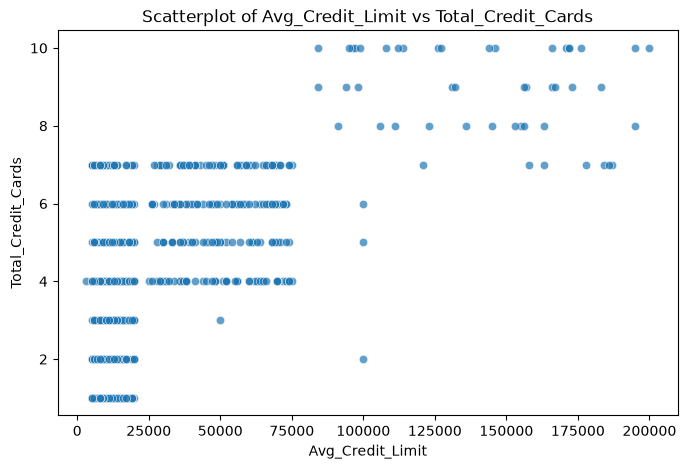

Correlation: 0.609


In [4]:
# ==========================================
# CELL 2: Q1 - Scatterplot & Linearity Check
# ==========================================
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df, x="Avg_Credit_Limit", y="Total_Credit_Cards", alpha=0.7
)
plt.title("Scatterplot of Avg_Credit_Limit vs Total_Credit_Cards")
plt.show()

# Correlation coefficient
corr = df["Avg_Credit_Limit"].corr(df["Total_Credit_Cards"])
print(f"Correlation: {corr:.3f}")

In [5]:
# ==========================================
# CELL 3: Data Preparation for Clustering
# ==========================================
# Drop non-feature columns
X = df.drop(columns=["Sl_No", "Customer Key"])

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

d:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than avai

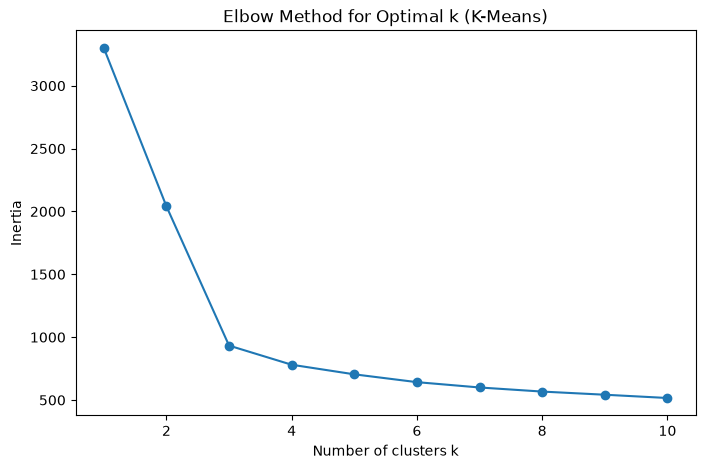

In [6]:
# ==========================================
# CELL 4: Q2 & Q3 - K-Means & Elbow Method
# ==========================================
inertias = []
K_range = range(1, 11)

for k in K_range:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(X_scaled)
  inertias.append(kmeans.inertia_)

# Plot Elbow Line Chart
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertias, marker="o", linestyle="-")
plt.xlabel("Number of clusters k")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k (K-Means)")
plt.show()

d:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


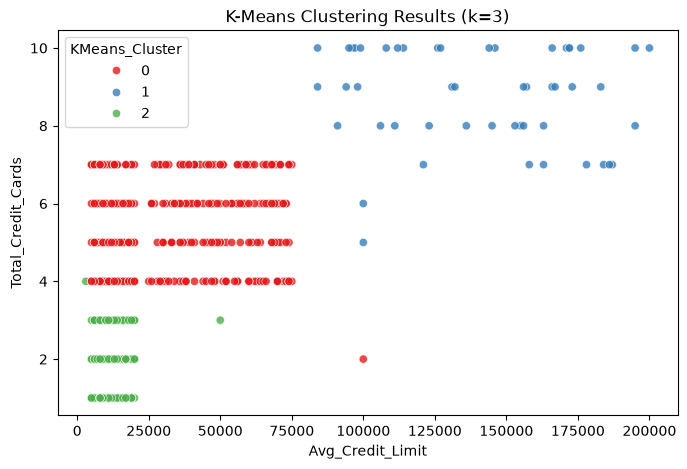

In [7]:
# Apply K-Means with optimal k = 3 and plot results
kmeans_optimal = KMeans(n_clusters=3, random_state=42, n_init=10)
df["KMeans_Cluster"] = kmeans_optimal.fit_predict(X_scaled)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Avg_Credit_Limit",
    y="Total_Credit_Cards",
    hue="KMeans_Cluster",
    palette="Set1",
    alpha=0.8,
)
plt.title("K-Means Clustering Results (k=3)")
plt.show()

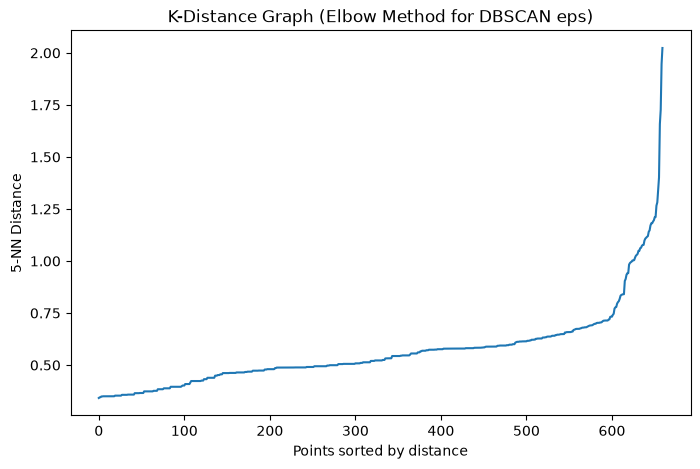

In [8]:
# ==========================================
# CELL 5: Q4 & Q5 - DBSCAN & Parameter Tuning
# ==========================================
# K-Distance graph (Elbow Method for DBSCAN eps)
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)
distances = np.sort(distances[:, 4], axis=0)

plt.figure(figsize=(8, 5))
plt.plot(distances)
plt.title("K-Distance Graph (Elbow Method for DBSCAN eps)")
plt.xlabel("Points sorted by distance")
plt.ylabel("5-NN Distance")
plt.show()

In [9]:
# ==========================================
# CELL 6: Q6 - Silhouette Score & DBI for DBSCAN
# ==========================================
db = DBSCAN(eps=1.2, min_samples=15)
labels = db.fit_predict(X_scaled)

core_mask = labels != -1
if len(set(labels[core_mask])) > 1:
  sil_score = silhouette_score(X_scaled[core_mask], labels[core_mask])
  dbi_score = davies_bouldin_score(X_scaled[core_mask], labels[core_mask])
  print(f"DBSCAN Silhouette Score : {sil_score:.3f}")
  print(f"DBSCAN Davies-Bouldin Index (DBI): {dbi_score:.3f}")
else:
  print("Insufficient clusters formed for scoring.")

DBSCAN Silhouette Score : 0.569
DBSCAN Davies-Bouldin Index (DBI): 0.509
